# Pittsburgh 311 Service Requests: Types, Geography, Repeated Reporting, and Seasonality

## Research focus

This insight report examines four questions using the City of Pittsburgh's archived 311 data:

1. Which service-request categories are most common?
2. How are reports distributed across Pittsburgh neighborhoods?
3. Which issue types most often receive repeated reports?
4. How does the composition of requests change by month?

The unit of analysis is an **issue group**. Each row represents one issue, while `num_requests` records the total number of parent and child reports connected to that issue. Accordingly, row counts are labeled **issue groups**, while sums of `num_requests` are labeled **reports**.

### Data sources

- [Western Pennsylvania Regional Data Center (WPRDC), 311 Data Archive](https://data.wprdc.org/dataset/311-data), resource ID `29462525-62a6-45bf-9b5e-ad2e1c06348d`.[^wprdc]
- [Esri ArcGIS REST service, Pittsburgh Neighborhoods layer](https://services1.arcgis.com/HmwnYiJTBZ4UkySc/ArcGIS/rest/services/Pittsburgh_Neighborhoods_and_Green_Spaces_WFL1/FeatureServer/7).[^boundaries]

[^wprdc]: Western Pennsylvania Regional Data Center. “311 Data Archive.” Accessed through the WPRDC CKAN API.
[^boundaries]: Esri ArcGIS REST Services Directory. “Pittsburgh Neighborhoods and Green Spaces,” Neighborhoods layer 7.

## 1. Reproducible data loading

The first run downloads every record from the WPRDC API in batches and stores a compressed raw-data snapshot. Later runs load that local snapshot, avoiding another full API download.


In [ ]:
import pandas as pd
from ckanapi import RemoteCKAN

rc = RemoteCKAN("https://data.wprdc.org/")

resource_id = "29462525-62a6-45bf-9b5e-ad2e1c06348d"
batch_size = 32000
offset = 0
all_records = []

while True:
    result = rc.action.datastore_search(
        resource_id=resource_id,
        limit=batch_size,
        offset=offset
    )

    records = result["records"]

    if not records:
        break

    all_records.extend(records)
    offset += len(records)

    print(f"Downloaded {len(all_records):,} of {result['total']:,} rows")

    if len(all_records) >= result["total"]:
        break

data_311 = pd.DataFrame(all_records)

print(data_311.shape)

Downloaded 32,000 of 815,417 rows
Downloaded 64,000 of 815,417 rows
Downloaded 96,000 of 815,417 rows
Downloaded 128,000 of 815,417 rows
Downloaded 160,000 of 815,417 rows
Downloaded 192,000 of 815,417 rows
Downloaded 224,000 of 815,417 rows
Downloaded 256,000 of 815,417 rows
Downloaded 288,000 of 815,417 rows
Downloaded 320,000 of 815,417 rows
Downloaded 352,000 of 815,417 rows
Downloaded 384,000 of 815,417 rows
Downloaded 416,000 of 815,417 rows
Downloaded 448,000 of 815,417 rows
Downloaded 480,000 of 815,417 rows
Downloaded 512,000 of 815,417 rows
Downloaded 544,000 of 815,417 rows
Downloaded 576,000 of 815,417 rows
Downloaded 608,000 of 815,417 rows
Downloaded 640,000 of 815,417 rows
Downloaded 672,000 of 815,417 rows
Downloaded 704,000 of 815,417 rows
Downloaded 736,000 of 815,417 rows
Downloaded 768,000 of 815,417 rows
Downloaded 800,000 of 815,417 rows
Downloaded 815,417 of 815,417 rows
(815417, 29)


## 2. Data cleaning and quality assessment


In [46]:
# Convert date fields used in the analysis.
date_columns = [
    "create_date_et",
    "last_action_et",
    "closed_date_et"
]

for column in date_columns:
    data_311[column] = pd.to_datetime(
        data_311[column],
        errors="coerce"
    )

# Convert numeric fields used in summaries and maps.
numeric_columns = ["num_requests", "latitude", "longitude"]

for column in numeric_columns:
    data_311[column] = pd.to_numeric(
        data_311[column],
        errors="coerce"
    )

# Standardize neighborhood labels. Empty strings become missing values.
data_311["neighborhood"] = (
    data_311["neighborhood"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Remove redundant UTC fields; this report consistently uses Eastern Time.
data_311 = data_311.drop(
    columns=[
        "create_date_utc",
        "last_action_utc",
        "closed_date_utc"
    ],
    errors="ignore"
)

# Remove duplicate record identifiers, if any.
data_311 = data_311.drop_duplicates(subset="_id").copy()

data_311.info()


<class 'pandas.DataFrame'>
RangeIndex: 815417 entries, 0 to 815416
Data columns (total 26 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   _id                815417 non-null  int64         
 1   group_id           815417 non-null  str           
 2   num_requests       815417 non-null  int64         
 3   parent_closed      815417 non-null  bool          
 4   status_name        815417 non-null  str           
 5   status_code        815417 non-null  int64         
 6   dept               811194 non-null  str           
 7   request_type_name  815417 non-null  str           
 8   request_type_id    815417 non-null  str           
 9   create_date_et     815417 non-null  datetime64[us]
 10  last_action_et     815417 non-null  datetime64[us]
 11  closed_date_et     722079 non-null  datetime64[us]
 12  origin             815417 non-null  str           
 13  street             500233 non-null  str           
 14 

### Dataset overview


In [47]:
project_summary = pd.DataFrame({
    "Metric": [
        "Records / issue groups",
        "Distinct group IDs",
        "Total connected reports",
        "Request types",
        "Neighborhood labels",
        "First creation date",
        "Last creation date"
    ],
    "Value": [
        f"{len(data_311):,}",
        f"{data_311['group_id'].nunique():,}",
        f"{data_311['num_requests'].sum():,.0f}",
        f"{data_311['request_type_name'].nunique():,}",
        f"{data_311['neighborhood'].nunique():,}",
        data_311["create_date_et"].min().date(),
        data_311["create_date_et"].max().date()
    ]
})

project_summary


,Metric,Value
0,Records / issue groups,"815,417"
1,Distinct group IDs,"815,417"
2,Total connected reports,"847,152"
3,Request types,345
4,Neighborhood labels,91
5,First creation date,2015-04-20
6,Last creation date,2025-03-10


### Missingness and validation checks


In [48]:
key_columns = [
    "group_id",
    "request_type_name",
    "num_requests",
    "create_date_et",
    "closed_date_et",
    "neighborhood",
    "latitude",
    "longitude",
    "status_name"
]

data_quality = pd.DataFrame({
    "data_type": data_311[key_columns].dtypes.astype(str),
    "missing_count": data_311[key_columns].isna().sum(),
    "missing_percent": (
        data_311[key_columns].isna().mean() * 100
    ).round(2),
    "unique_values": data_311[key_columns].nunique()
})

print("Duplicate _id values:", data_311["_id"].duplicated().sum())
print("Duplicate group_id values:", data_311["group_id"].duplicated().sum())
print("num_requests below 1:", (data_311["num_requests"] < 1).sum())

data_quality


Duplicate _id values: 0
Duplicate group_id values: 0
num_requests below 1: 0


,data_type,missing_count,missing_percent,unique_values
group_id,str,0,0.00,815417
request_type_name,str,0,0.00,345
num_requests,int64,0,0.00,40
create_date_et,datetime64[us],0,0.00,640219
closed_date_et,datetime64[us],93338,11.45,416320
neighborhood,string,37372,4.58,91
latitude,float64,31408,3.85,488324
longitude,float64,31408,3.85,504508
status_name,str,0,0.00,4


### Geographic fields

Neighborhood is the primary geography because it is intuitive for communicating local service patterns. Other geographic fields are retained in the cleaned data for possible administrative or census-based analyses.


In [49]:
geographic_summary = pd.Series({
    "Neighborhoods": data_311["neighborhood"].nunique(),
    "Wards": data_311["ward"].nunique(),
    "Council districts": data_311["council_district"].nunique(),
    "Police zones": data_311["police_zone"].nunique(),
    "Census tracts": data_311["census_tract"].nunique()
}, name="Unique values").to_frame()

geographic_summary


,Unique values
Neighborhoods,91
Wards,34
Council districts,10
Police zones,7
Census tracts,260


## 3. Request-type composition

The frequency analysis counts issue groups, not the total number of parent and child reports. Percent labels therefore use all issue groups as the denominator.


In [50]:
data_311['request_type_name'].value_counts().head(20)


request_type_name
Weeds/Debris                            77513
Potholes                                67502
Missed Refuse Pick Up                   42185
Snow/Ice removal                        34942
Building Maintenance                    28863
Refuse Violations                       26598
Abandoned Vehicle (parked on street)    23768
Illegal Parking                         21289
Missed Recycling Pick Up                17987
Street Light - Repair                   17903
Litter, Public Property                 17852
Replace/Repair a Sign                   13918
Building Without a Permit               11791
Overgrowth                              10771
Paving Request                           9538
Pruning (city tree)                      8828
City Source (CDBG)                       8646
Early Set Out                            8475
Excessive Noise/Disturbances             8048
Dead Animal                              7925
Name: count, dtype: int64

In [51]:
data_311['request_type_name'].nunique()


345

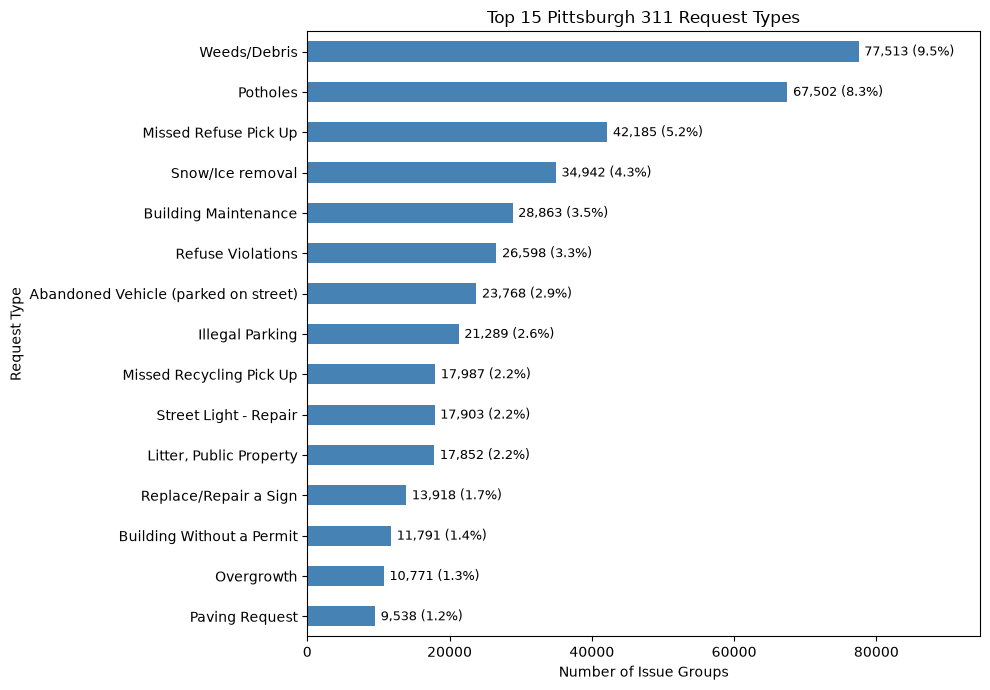

In [80]:
import matplotlib.pyplot as plt

top15_requests = (
    data_311["request_type_name"]
    .value_counts()
    .head(15)
    .sort_values()
)

total_issue_groups = len(data_311)

fig_request_types, ax = plt.subplots(figsize=(10, 7))

top15_requests.plot(
    kind="barh",
    color="steelblue",
    ax=ax
)

labels = [
    f"{count:,} ({count / total_issue_groups * 100:.1f}%)"
    for count in top15_requests
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=4,
    fontsize=9
)

ax.set_xlim(0, top15_requests.max() * 1.22)
ax.set_title("Top 15 Pittsburgh 311 Request Types")
ax.set_xlabel("Number of Issue Groups")
ax.set_ylabel("Request Type")

plt.tight_layout()
fig_request_types.savefig(
     "top15_request_types.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 4. Repeated reporting

`num_requests` is the total number of reports connected to an issue, including its parent and child tickets. Most issues receive only one report, while a small group receives repeated reports. An issue is classified as **high repeat** when `num_requests >= 5`.


In [53]:
data_311["num_requests"].describe()


count    815417.000000
mean          1.038919
std           0.419785
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max         175.000000
Name: num_requests, dtype: float64

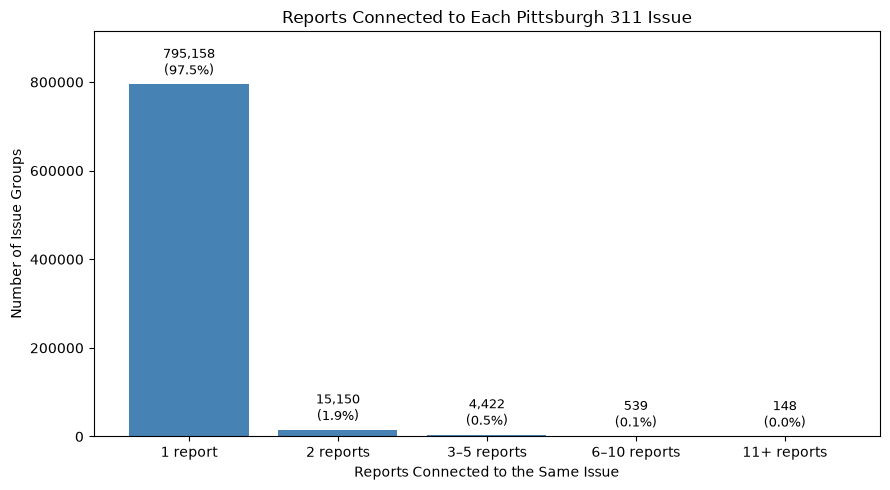

In [54]:
import numpy as np

request_counts = data_311["num_requests"].dropna()
request_counts = request_counts[request_counts >= 1]

report_groups = pd.cut(
    request_counts,
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=[
        "1 report",
        "2 reports",
        "3–5 reports",
        "6–10 reports",
        "11+ reports"
    ]
)

group_counts = report_groups.value_counts().sort_index()
group_percent = group_counts / group_counts.sum() * 100

fig_report_distribution, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(group_counts.index, group_counts.values, color="steelblue")

ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percent:.1f}%)"
        for count, percent in zip(group_counts, group_percent)
    ],
    padding=4,
    fontsize=9
)

ax.set_title("Reports Connected to Each Pittsburgh 311 Issue")
ax.set_xlabel("Reports Connected to the Same Issue")
ax.set_ylabel("Number of Issue Groups")
ax.set_ylim(0, group_counts.max() * 1.15)

plt.tight_layout()
fig_report_distribution.savefig(
    "reports_per_issue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


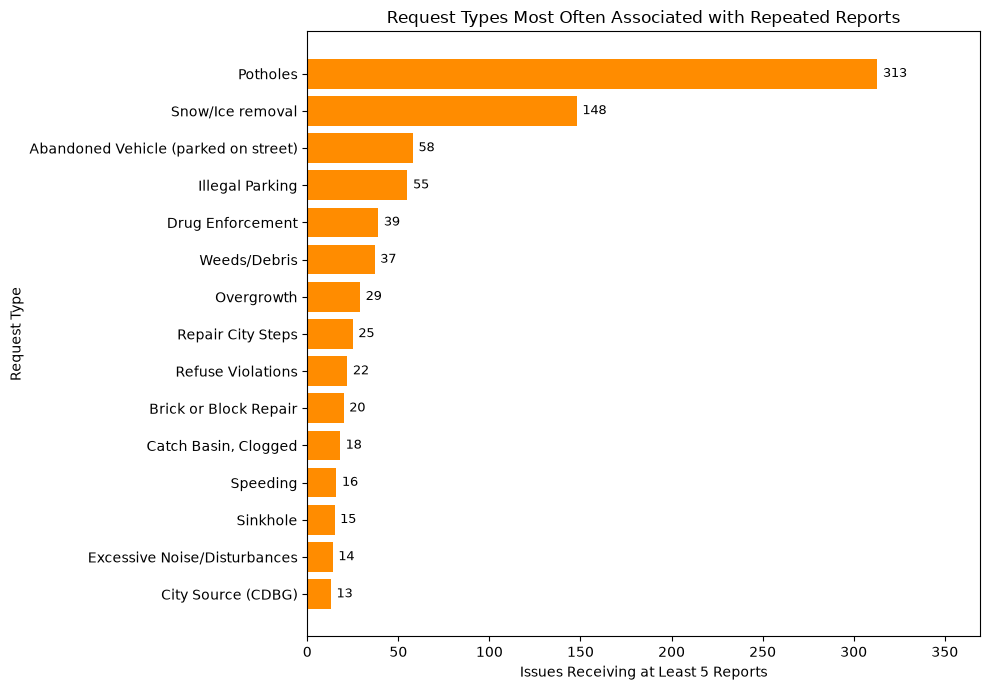

,high_repeat_issues,total_reports,median_reports_per_issue
request_type_name,,,
Potholes,313,2697,7.0
Snow/Ice removal,148,1298,6.0
Abandoned Vehicle (parked on street),58,372,6.0
Illegal Parking,55,532,6.0
Drug Enforcement,39,320,7.0
Weeds/Debris,37,251,6.0
Overgrowth,29,164,5.0
Repair City Steps,25,178,6.0
Refuse Violations,22,133,6.0


In [55]:
high_repeat_requests = data_311[
    data_311["num_requests"] >= 5
].copy()

high_repeat_summary = (
    high_repeat_requests
    .groupby("request_type_name")
    .agg(
        high_repeat_issues=("group_id", "nunique"),
        total_reports=("num_requests", "sum"),
        median_reports_per_issue=("num_requests", "median")
    )
    .sort_values("high_repeat_issues", ascending=False)
)

top15_high_repeat = high_repeat_summary.head(15)
plot_high_repeat = top15_high_repeat.sort_values("high_repeat_issues")

fig_high_repeat, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    plot_high_repeat.index,
    plot_high_repeat["high_repeat_issues"],
    color="darkorange"
)

ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in plot_high_repeat["high_repeat_issues"]],
    padding=4,
    fontsize=9
)

ax.set_xlim(0, plot_high_repeat["high_repeat_issues"].max() * 1.18)
ax.set_title("Request Types Most Often Associated with Repeated Reports")
ax.set_xlabel("Issues Receiving at Least 5 Reports")
ax.set_ylabel("Request Type")

plt.tight_layout()
fig_high_repeat.savefig(
     "high_repeat_request_types.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

top15_high_repeat


## 5. Neighborhood patterns

Neighborhood totals are calculated by summing `num_requests`; this measures all reports connected to issues in each neighborhood. These are raw totals and are not adjusted for neighborhood population, area, or road mileage.


In [56]:
import json
import requests
import geopandas as gpd
import plotly.express as px
import plotly.graph_objects as go

map_data = data_311.dropna(
    subset=["neighborhood", "num_requests"]
).copy()

neighborhood_summary = (
    map_data
    .groupby("neighborhood", as_index=False)
    .agg(
        total_reports=("num_requests", "sum"),
        issue_groups=("group_id", "nunique")
    )
)

neighborhood_summary.sort_values(
    "total_reports",
    ascending=False
).head(10)


,neighborhood,total_reports,issue_groups
13,Brookline,34580,32245
15,Carrick,32831,31017
73,South Side Slopes,30556,29508
72,South Side Flats,30400,29758
77,Squirrel Hill South,30233,29226
9,Bloomfield,23659,22841
16,Central Business District,22603,22109
53,Mount Washington,22319,21368
7,Beechview,20203,19139
68,Shadyside,18387,17865


In [59]:
from pathlib import Path

NEIGHBORHOOD_PATH = Path("pittsburgh_neighborhoods.geojson")

neighborhood_url = (
    "https://services1.arcgis.com/"
    "HmwnYiJTBZ4UkySc/ArcGIS/rest/services/"
    "Pittsburgh_Neighborhoods_and_Green_Spaces_WFL1/"
    "FeatureServer/7/query"
)

if NEIGHBORHOOD_PATH.exists():
    neighborhood_geojson = json.loads(
        NEIGHBORHOOD_PATH.read_text(encoding="utf-8")
    )
else:
    response = requests.get(
        neighborhood_url,
        params={
            "where": "1=1",
            "outFields": "hood",
            "returnGeometry": "true",
            "outSR": "4326",
            "f": "geojson"
        },
        timeout=120
    )
    response.raise_for_status()
    neighborhood_geojson = response.json()
    NEIGHBORHOOD_PATH.write_text(
        json.dumps(neighborhood_geojson),
        encoding="utf-8"
    )

neighborhood_boundaries = gpd.GeoDataFrame.from_features(
    neighborhood_geojson["features"],
    crs="EPSG:4326"
)[["hood", "geometry"]]

neighborhood_boundaries.head()


,hood,geometry
0,Chateau,"POLYGON ((-80.02999 40.45909, -80.02989 40.458..."
1,Summer Hill,"POLYGON ((-80.01078 40.49975, -80.01073 40.499..."
2,Northview Heights,"POLYGON ((-80.00327 40.48271, -80.00325 40.482..."
3,Spring Hill-City View,"POLYGON ((-79.99761 40.4746, -79.99761 40.4745..."
4,Perry South,"POLYGON ((-80.01422 40.47745, -80.01435 40.477..."


In [60]:
unmatched_neighborhoods = sorted(
    set(neighborhood_summary["neighborhood"])
    - set(neighborhood_boundaries["hood"])
)

print("Neighborhood labels that did not match the boundary file:")
print(unmatched_neighborhoods)


Neighborhood labels that did not match the boundary file:
['Mount Oliver Borough']


Blank neighborhood values are treated as missing. `Mount Oliver Borough` is not represented because it does not match a polygon in the selected City of Pittsburgh neighborhood boundary layer.


In [61]:
neighborhood_map = neighborhood_boundaries.merge(
    neighborhood_summary,
    left_on="hood",
    right_on="neighborhood",
    how="left"
)

for column in ["total_reports", "issue_groups"]:
    neighborhood_map[column] = (
        neighborhood_map[column]
        .fillna(0)
        .astype(int)
    )

projected_map = neighborhood_map.to_crs("EPSG:2272")
label_points_projected = projected_map.representative_point()

label_points = gpd.GeoDataFrame(
    neighborhood_map[["hood"]].copy(),
    geometry=label_points_projected,
    crs="EPSG:2272"
).to_crs("EPSG:4326")


In [62]:
map_geojson = json.loads(
    neighborhood_map[["hood", "geometry"]].to_json()
)

fig_neighborhood_map = px.choropleth_map(
    neighborhood_map,
    geojson=map_geojson,
    locations="hood",
    featureidkey="properties.hood",
    color="total_reports",
    hover_name="hood",
    hover_data={
        "total_reports": ":,",
        "issue_groups": ":,",
        "hood": False
    },
    color_continuous_scale="YlOrRd",
    map_style="carto-positron",
    center={"lat": 40.4406, "lon": -79.9959},
    zoom=10,
    opacity=0.75,
    labels={
        "total_reports": "311 reports",
        "issue_groups": "Issue groups"
    },
    title="Total Pittsburgh 311 Reports by Neighborhood",
    height=750
)

fig_neighborhood_map.update_traces(
    marker_line_width=1,
    marker_line_color="white"
)

fig_neighborhood_map.add_trace(
    go.Scattermap(
        lat=label_points.geometry.y,
        lon=label_points.geometry.x,
        mode="text",
        text=label_points["hood"],
        textfont={"size": 9, "color": "black"},
        hoverinfo="skip",
        showlegend=False
    )
)

fig_neighborhood_map.update_layout(
    margin={"r": 0, "t": 60, "l": 0, "b": 0},
    coloraxis_colorbar={"title": "311 reports"}
)

fig_neighborhood_map.write_html(
     "neighborhood_report_map.html"
)
fig_neighborhood_map.show()


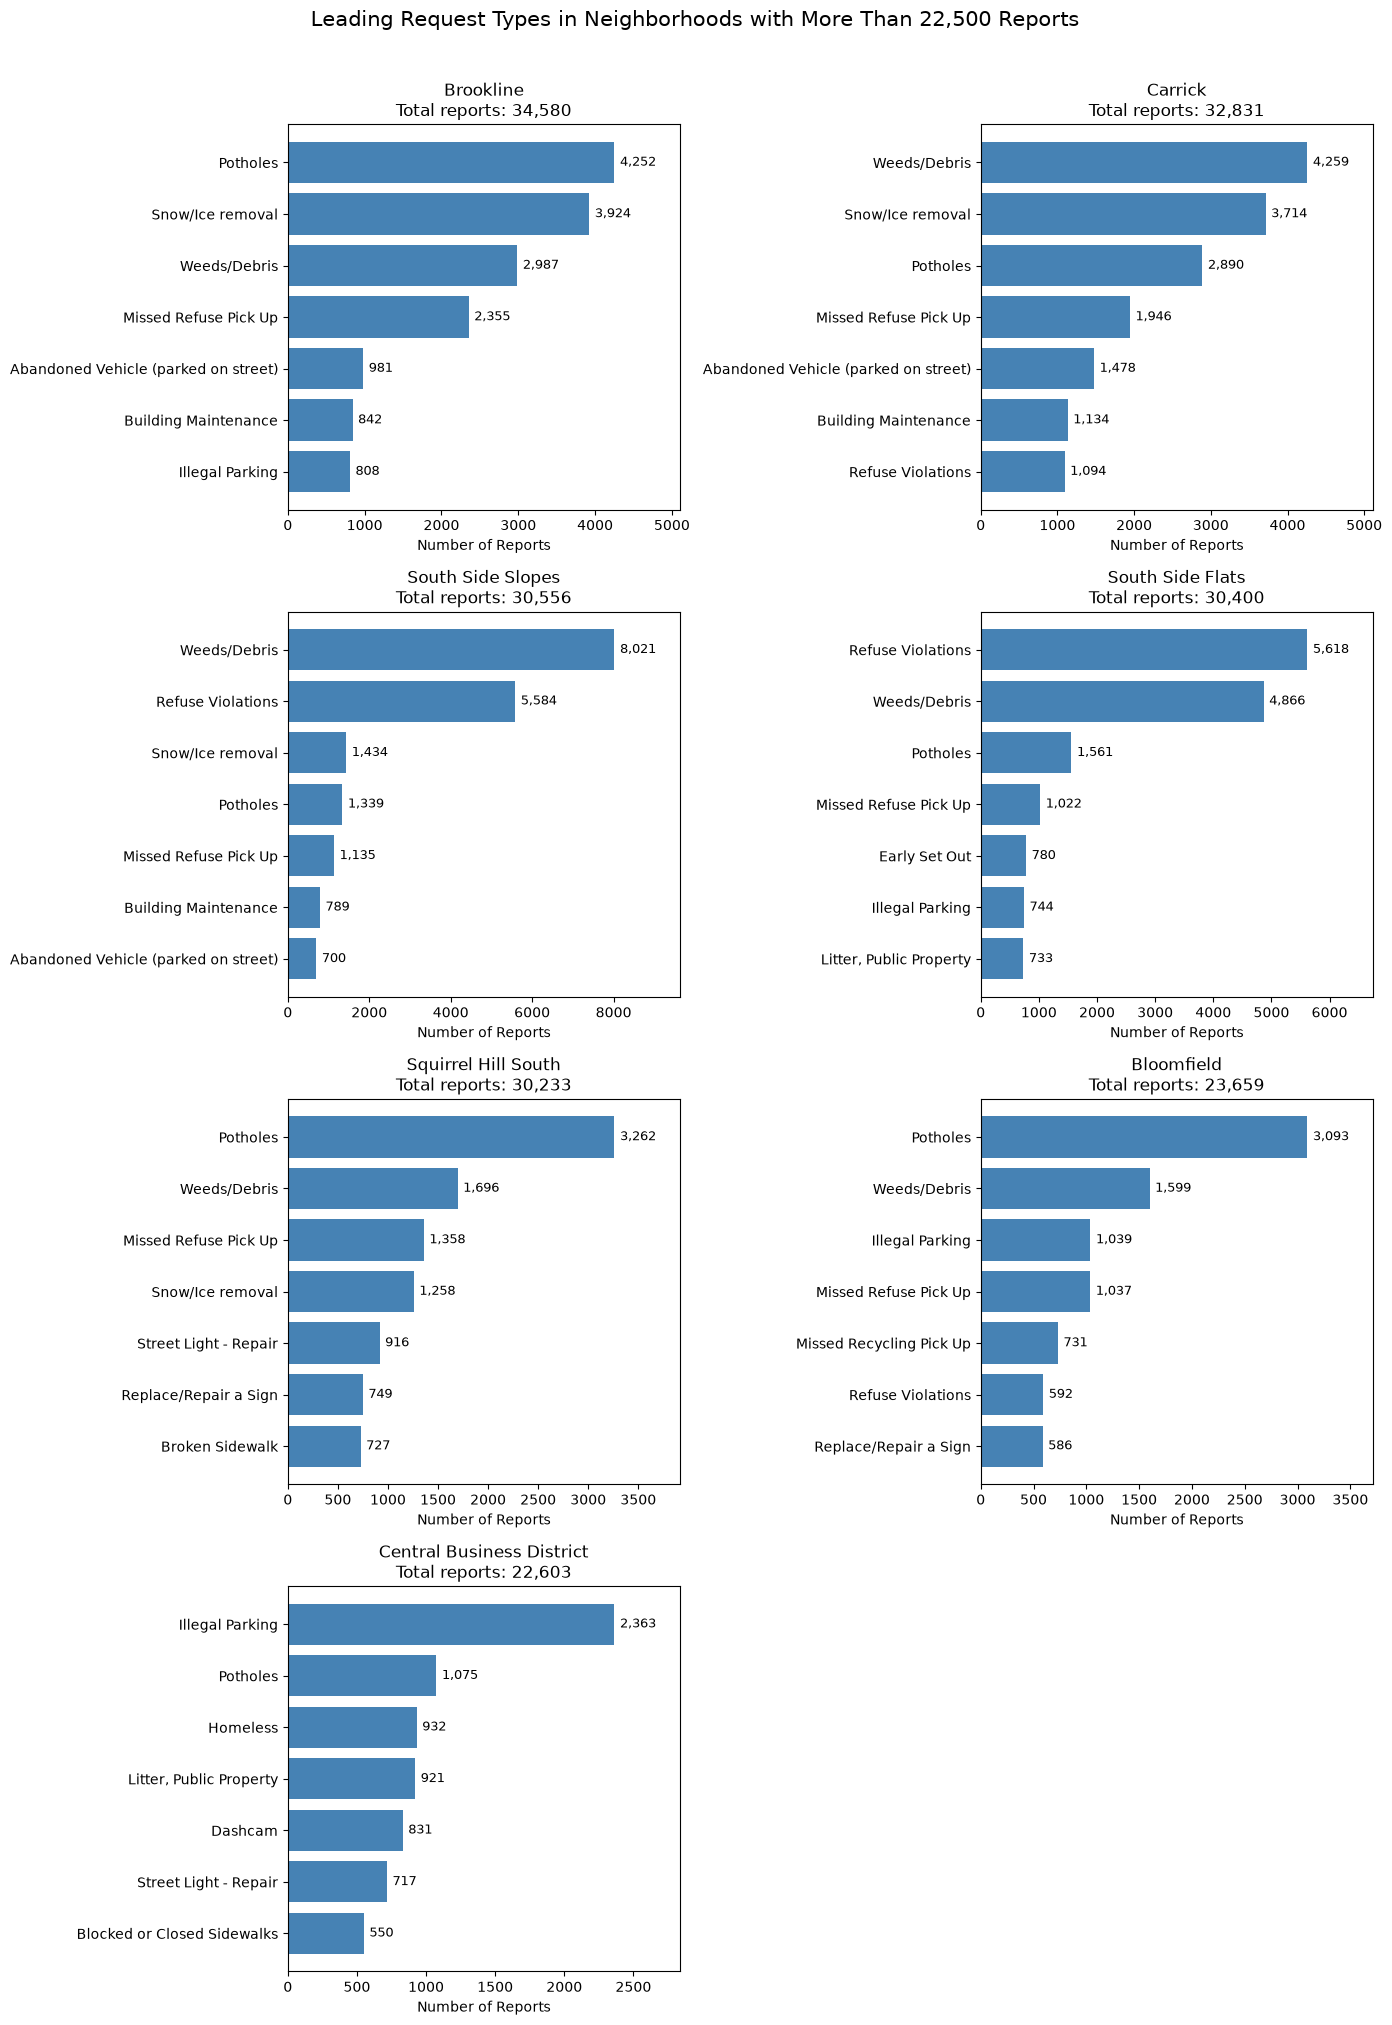

In [63]:
import math

neighborhood_totals = (
    map_data
    .groupby("neighborhood")["num_requests"]
    .sum()
    .sort_values(ascending=False)
)

high_volume_neighborhoods = neighborhood_totals[
    neighborhood_totals > 22_500
].index.tolist()

top7_by_neighborhood = (
    map_data[
        map_data["neighborhood"].isin(high_volume_neighborhoods)
    ]
    .groupby(
        ["neighborhood", "request_type_name"],
        as_index=False
    )["num_requests"]
    .sum()
    .rename(columns={"num_requests": "report_count"})
    .sort_values(
        ["neighborhood", "report_count"],
        ascending=[True, False]
    )
    .groupby("neighborhood", group_keys=False)
    .head(7)
)

if not high_volume_neighborhoods:
    print("No neighborhoods have more than 22,500 reports.")
else:
    ncols = 2
    nrows = math.ceil(len(high_volume_neighborhoods) / ncols)
    fig_high_volume, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(14, 5 * nrows)
    )
    axes = axes.flatten() if len(high_volume_neighborhoods) > 1 else [axes]

    for ax, neighborhood in zip(axes, high_volume_neighborhoods):
        plot_data = (
            top7_by_neighborhood[
                top7_by_neighborhood["neighborhood"] == neighborhood
            ]
            .sort_values("report_count")
        )
        bars = ax.barh(
            plot_data["request_type_name"],
            plot_data["report_count"],
            color="steelblue"
        )
        ax.bar_label(
            bars,
            labels=[f"{value:,.0f}" for value in plot_data["report_count"]],
            padding=4,
            fontsize=9
        )
        ax.set_title(
            f"{neighborhood}\n"
            f"Total reports: {neighborhood_totals.loc[neighborhood]:,.0f}"
        )
        ax.set_xlabel("Number of Reports")
        ax.set_ylabel("")
        ax.set_xlim(0, plot_data["report_count"].max() * 1.20)

    for ax in axes[len(high_volume_neighborhoods):]:
        ax.remove()

    fig_high_volume.suptitle(
        "Leading Request Types in Neighborhoods with More Than 22,500 Reports",
        fontsize=15,
        y=1.01
    )
    plt.tight_layout()
    fig_high_volume.savefig(
         "high_volume_neighborhood_request_types.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


## 6. Geography of high-repeat issues

The following static map shows issue groups receiving at least five reports. Point size represents the number of connected reports; color identifies request type for the 15 categories with the largest number of high-repeat issues. Other categories appear in gray.


Top 15 high-repeat request types:


,high_repeat_issues,total_reports,median_reports_per_issue
request_type_name,,,
Potholes,313,2697,7.0
Snow/Ice removal,148,1298,6.0
Abandoned Vehicle (parked on street),58,372,6.0
Illegal Parking,55,532,6.0
Drug Enforcement,39,320,7.0
Weeds/Debris,37,251,6.0
Overgrowth,29,164,5.0
Repair City Steps,25,178,6.0
Refuse Violations,22,133,6.0


High-repeat issues: 1,088
Issues with usable coordinates: 1,085
Coordinate coverage: 99.7%


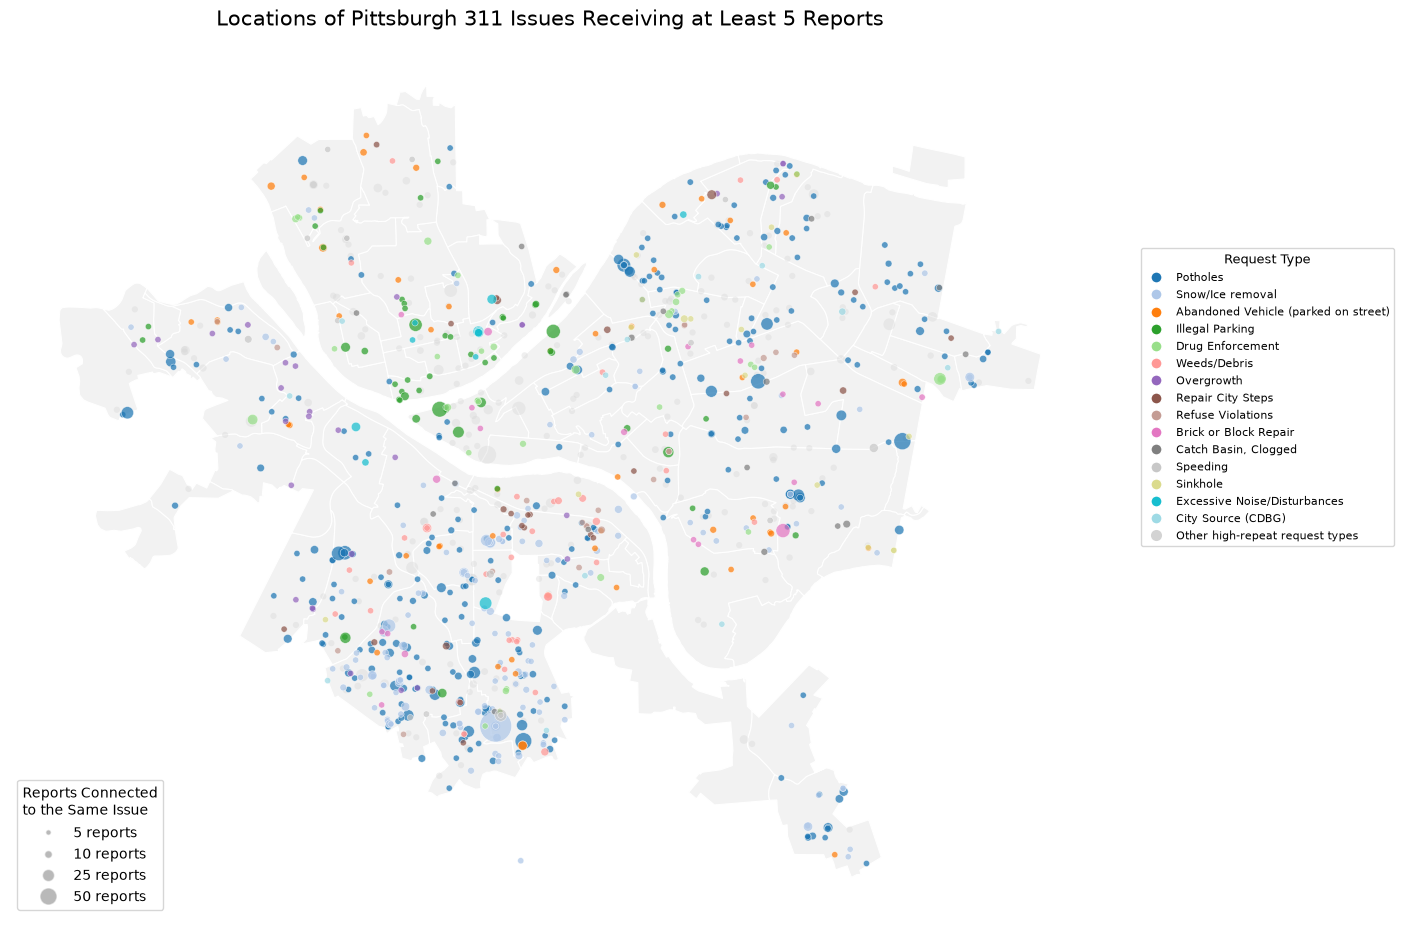

In [64]:
from matplotlib.lines import Line2D

repeated_data = data_311.dropna(
    subset=["request_type_name", "num_requests"]
).copy()

high_repeat_requests = repeated_data[
    repeated_data["num_requests"] >= 5
].copy()

high_repeat_summary = (
    high_repeat_requests
    .groupby("request_type_name")
    .agg(
        high_repeat_issues=("group_id", "nunique"),
        total_reports=("num_requests", "sum"),
        median_reports_per_issue=("num_requests", "median")
    )
    .sort_values("high_repeat_issues", ascending=False)
)

top15_high_repeat = high_repeat_summary.head(15)
top15_types = top15_high_repeat.index.tolist()

print("Top 15 high-repeat request types:")
display(top15_high_repeat)

repeated_points = high_repeat_requests.dropna(
    subset=["latitude", "longitude"]
).copy()

repeated_points = repeated_points[
    repeated_points["latitude"].between(40.3, 40.6)
    & repeated_points["longitude"].between(-80.2, -79.7)
].copy()

print("High-repeat issues:", f"{len(high_repeat_requests):,}")
print("Issues with usable coordinates:", f"{len(repeated_points):,}")
print(
    "Coordinate coverage:",
    f"{len(repeated_points) / len(high_repeat_requests) * 100:.1f}%"
)

repeated_points = gpd.GeoDataFrame(
    repeated_points,
    geometry=gpd.points_from_xy(
        repeated_points["longitude"],
        repeated_points["latitude"]
    ),
    crs="EPSG:4326"
)

projected_crs = "EPSG:2272"
static_boundaries = neighborhood_boundaries.to_crs(projected_crs)
static_points = repeated_points.to_crs(projected_crs)

static_points["marker_size"] = np.clip(
    static_points["num_requests"] * 3,
    20,
    600
)

color_values = plt.get_cmap("tab20")(
    np.linspace(0, 1, len(top15_types))
)
type_colors = dict(zip(top15_types, color_values))

fig_repeat_map, ax = plt.subplots(figsize=(15, 11))
static_boundaries.plot(
    ax=ax,
    facecolor="#f2f2f2",
    edgecolor="white",
    linewidth=0.8,
    zorder=1
)

other_points = static_points[
    ~static_points["request_type_name"].isin(top15_types)
]
if not other_points.empty:
    ax.scatter(
        other_points.geometry.x,
        other_points.geometry.y,
        s=other_points["marker_size"],
        color="lightgray",
        alpha=0.35,
        edgecolor="none",
        zorder=2
    )

for request_type in top15_types:
    type_points = static_points[
        static_points["request_type_name"] == request_type
    ]
    if type_points.empty:
        continue
    ax.scatter(
        type_points.geometry.x,
        type_points.geometry.y,
        s=type_points["marker_size"],
        color=type_colors[request_type],
        alpha=0.72,
        edgecolor="white",
        linewidth=0.4,
        zorder=3
    )

color_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=type_colors[request_type],
        markeredgecolor="white",
        markersize=8,
        label=request_type
    )
    for request_type in top15_types
]
color_handles.append(
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor="lightgray",
        markeredgecolor="none",
        markersize=8,
        label="Other high-repeat request types"
    )
)

fig_repeat_map.legend(
    handles=color_handles,
    title="Request Type",
    loc="center left",
    bbox_to_anchor=(0.76, 0.56),
    frameon=True,
    fontsize=8,
    title_fontsize=9
)

size_values = [5, 10, 25, 50]

size_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor="gray",
        markeredgecolor="white",
        alpha=0.55,
        markersize=np.sqrt(value * 3),
        label=f"{value} reports"
    )
    for value in size_values
]

ax.legend(
    handles=size_handles,
    title="Reports Connected\nto the Same Issue",
    loc="lower left",
    frameon=True
)

ax.set_title(
    "Locations of Pittsburgh 311 Issues Receiving at Least 5 Reports",
    fontsize=15,
    pad=15
)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout(
    rect=[0, 0, 0.74, 1]
)

fig_repeat_map.savefig(
    "high_repeat_issue_locations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Temporal patterns and seasonal association

The annual trend uses complete calendar years from 2016 through 2024. The archive begins partway through 2015, and its 2025 creation dates end in early February, so those partial years are excluded from year-to-year comparisons.


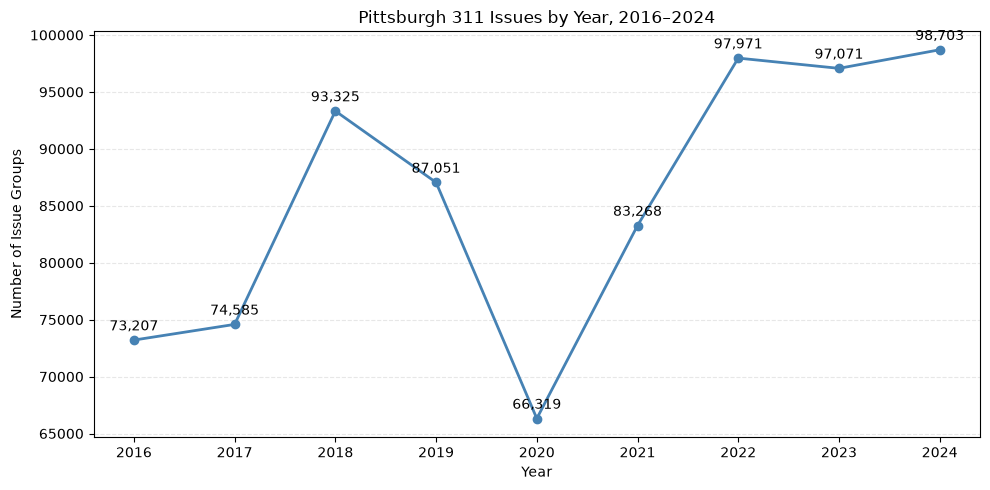

In [65]:
full_year_data = data_311[
    data_311["create_date_et"].dt.year.between(2016, 2024)
].copy()

yearly_issues = (
    full_year_data
    .groupby(full_year_data["create_date_et"].dt.year)["group_id"]
    .nunique()
)

fig_yearly, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    yearly_issues.index,
    yearly_issues.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

for year, count in yearly_issues.items():
    ax.annotate(
        f"{count:,}",
        (year, count),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Pittsburgh 311 Issues by Year, 2016–2024")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Issue Groups")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig_yearly.savefig(
     "yearly_issue_groups.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Association between request type and month

Both variables are categorical, so a chi-square test evaluates whether their distributions are independent, while Cramér's V summarizes association strength. The analysis uses the 10 most common request types and the complete years 2016–2024. Because the dataset is very large, practical interpretation emphasizes Cramér's V and the heatmap rather than statistical significance alone.[^chi]

[^chi]: SciPy documentation, [`scipy.stats.chi2_contingency`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html). Cramér's V is calculated from the chi-square statistic and contingency-table dimensions.


In [66]:
import calendar
import seaborn as sns
from scipy.stats import chi2_contingency

season_data = data_311.copy()
season_data["year"] = season_data["create_date_et"].dt.year
season_data["month"] = season_data["create_date_et"].dt.month
season_data = season_data[
    season_data["year"].between(2016, 2024)
].copy()

top10_types = (
    season_data["request_type_name"]
    .value_counts()
    .head(10)
    .index
)

season_top10 = season_data[
    season_data["request_type_name"].isin(top10_types)
].copy()

month_type_table = pd.crosstab(
    season_top10["month"],
    season_top10["request_type_name"]
).reindex(range(1, 13), fill_value=0)

month_type_table


request_type_name,Abandoned Vehicle (parked on street),Building Maintenance,Illegal Parking,"Litter, Public Property",Missed Recycling Pick Up,Missed Refuse Pick Up,Potholes,Refuse Violations,Snow/Ice removal,Weeds/Debris
month,,,,,,,,,,
1,1636,1776,1501,1022,1386,2781,4824,1811,14253,2151
2,1766,2481,1767,1264,1504,3230,8832,1939,9320,2499
3,1942,2701,1816,1605,1183,2724,8649,2189,1379,3529
4,2161,2457,1637,1604,1227,2832,8856,1994,27,3897
5,2072,2720,1671,1471,1265,3281,7585,1844,1,11818
6,2122,2801,1667,1633,1333,3804,5629,1997,1,12634
7,2164,2490,1619,1735,1747,4367,4605,2490,1,11651
8,2288,2775,2003,1749,1661,4178,3515,2913,1,11304
9,2026,2304,2160,1565,1432,3474,2531,1876,0,7338


In [67]:
chi2, p_value, dof, expected = chi2_contingency(month_type_table)

n = month_type_table.to_numpy().sum()
rows, columns = month_type_table.shape
cramers_v = np.sqrt(
    (chi2 / n) / min(rows - 1, columns - 1)
)

print(f"Chi-square: {chi2:,.2f}")
print("p-value: < 0.001" if p_value < 0.001 else f"p-value: {p_value:.3f}")
print(f"Cramér's V: {cramers_v:.3f}")
print(f"Minimum expected cell count: {expected.min():,.1f}")


Chi-square: 122,740.76
p-value: < 0.001
Cramér's V: 0.201
Minimum expected cell count: 856.7


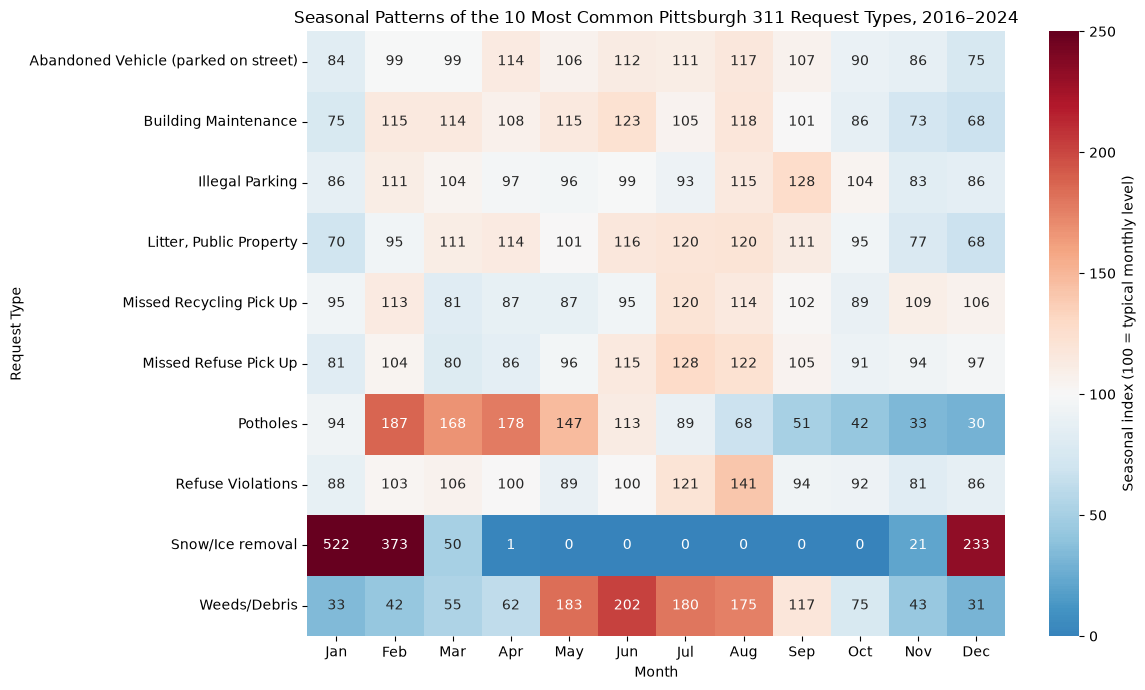

In [68]:
all_dates = pd.date_range(
    start="2016-01-01",
    end="2024-12-31",
    freq="D"
)

days_per_month = (
    pd.Series(all_dates.month)
    .value_counts()
    .sort_index()
)

daily_rate = month_type_table.div(days_per_month, axis=0)

seasonal_index = (
    daily_rate
    .div(daily_rate.mean(axis=0), axis=1)
    * 100
)

heatmap_data = seasonal_index.T
heatmap_data.columns = calendar.month_abbr[1:13]

fig_seasonal, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=100,
    vmin=0,
    vmax=250,
    annot=True,
    fmt=".0f",
    cbar_kws={
        "label": "Seasonal index (100 = typical monthly level)"
    },
    ax=ax
)

ax.set_title(
    "Seasonal Patterns of the 10 Most Common "
    "Pittsburgh 311 Request Types, 2016–2024"
)
ax.set_xlabel("Month")
ax.set_ylabel("Request Type")

plt.tight_layout()
fig_seasonal.savefig(
     "request_type_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


The seasonal index makes different request types comparable: 100 represents a typical monthly daily rate, 150 is approximately 50% above that level, and 50 is approximately 50% below it. Colors are capped at 250 for readability, but cell labels retain the actual index values. Snow/ice removal is concentrated in winter, potholes rise most strongly from February through spring, and weeds/debris peak during the warmer months. Refuse, recycling, parking, and building-related requests exhibit weaker seasonality.


## 8. Limitations

- Neighborhood totals are not adjusted for population, land area, road mileage, or differential willingness to contact 311. They should not be interpreted as neighborhood performance rankings.
- A row represents an issue group, whereas `num_requests` represents all connected reports. These measures are kept separate throughout the analysis.
- `last_action_et` is an administrative activity timestamp and does not necessarily indicate resolution.
- The 2015 and 2025 observations cover partial years and are excluded from complete-year trend and seasonality comparisons.
- Geographic coordinates and neighborhood labels are missing for some records. Point maps therefore describe only records with usable coordinates.
- Chi-square and Cramér's V describe association, not causation. Seasonal patterns may reflect weather, service schedules, reporting behavior, or other unmeasured factors.


## Appendix A. Closure fields and time to last recorded action


In [69]:
closure_missing = data_311["closed_date_et"].isna().sum()

pd.Series({
    "Missing closure dates": closure_missing,
    "Missing closure dates (%)": round(
        closure_missing / len(data_311) * 100,
        2
    )
})


Missing closure dates        93338.00
Missing closure dates (%)       11.45
dtype: float64

The following measure is **time to the last recorded action**, not resolution time. The last action may be an update, administrative change, or later system activity.


In [70]:
data_311["time_to_last_action"] = (
    data_311["last_action_et"]
    - data_311["create_date_et"]
)

data_311["time_to_last_action"].describe()


count                      815417
mean      84 days 06:11:05.889281
std      243 days 01:15:44.062241
min               0 days 00:00:00
25%               1 days 02:14:00
50%               7 days 02:11:00
75%              42 days 21:39:00
max            3529 days 19:57:00
Name: time_to_last_action, dtype: object

In [71]:
duration_summary = (
    data_311
    .groupby("request_type_name")
    .agg(
        issue_groups=("group_id", "nunique"),
        median_time_to_last_action=("time_to_last_action", "median")
    )
)

# Require at least 100 issue groups to reduce unstable comparisons.
duration_summary[
    duration_summary["issue_groups"] >= 100
].sort_values(
    "median_time_to_last_action",
    ascending=False
).head(15)


,issue_groups,median_time_to_last_action
request_type_name,,
"Graffiti, Documentation (DO NOT USE)",312,1009 days 14:49:30
Sidewalk/Curb/ADA Ramp Maintenance,3032,553 days 10:03:00
County Maintenance,278,446 days 14:19:30
Dead Tree (3TB),1554,358 days 07:04:00
Water Runoff in ROW,304,340 days 23:27:30
Homeless,3351,317 days 23:44:00
Guide Rail,690,216 days 00:49:30
"ADA Ramp, Installation",259,204 days 00:46:00
Lead Testing Kit,233,198 days 00:11:00


## Appendix B. Case status


In [72]:
status_summary = (
    data_311["status_name"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="issue_groups")
)

status_summary["percent"] = (
    status_summary["issue_groups"] / len(data_311) * 100
).round(2)

status_summary


,status,issue_groups,percent
0,closed,722079,88.55
1,in progress,47555,5.83
2,open,45304,5.56
3,on hold,479,0.06


The table below compares status composition for the 15 most common request types. Row percentages are used because raw counts are dominated by the most frequent request categories.


In [73]:
top15_status_types = (
    data_311["request_type_name"]
    .value_counts()
    .head(15)
    .index
)

top15_status_data = data_311[
    data_311["request_type_name"].isin(top15_status_types)
]

status_percent = (
    pd.crosstab(
        top15_status_data["request_type_name"],
        top15_status_data["status_name"],
        normalize="index"
    )
    .round(1)
)

status_percent.loc[top15_status_types]


status_name,closed,in progress,on hold,open
request_type_name,,,,
Weeds/Debris,0.9,0.1,0.0,0.0
Potholes,1.0,0.0,0.0,0.0
Missed Refuse Pick Up,1.0,0.0,0.0,0.0
Snow/Ice removal,1.0,0.0,0.0,0.0
Building Maintenance,0.8,0.2,0.0,0.0
Refuse Violations,1.0,0.0,0.0,0.0
Abandoned Vehicle (parked on street),0.6,0.1,0.0,0.3
Illegal Parking,0.8,0.1,0.0,0.1
Missed Recycling Pick Up,1.0,0.0,0.0,0.0


## Appendix C. Thank-you request categories


In [74]:
thank_you_mask = data_311["request_type_name"].str.contains(
    r"thank\s*you|thanks",
    case=False,
    na=False,
    regex=True
)

thank_you_data = data_311[thank_you_mask]

thank_you_summary = (
    thank_you_data["request_type_name"]
    .value_counts()
    .rename_axis("request_type")
    .reset_index(name="issue_groups")
)

thank_you_summary["percent_of_all_issues"] = (
    thank_you_summary["issue_groups"] / len(data_311) * 100
)
thank_you_summary["percent_of_thank_you_issues"] = (
    thank_you_summary["issue_groups"] / len(thank_you_data) * 100
)

thank_you_summary.round(2)


,request_type,issue_groups,percent_of_all_issues,percent_of_thank_you_issues
0,Thank you - DPW,1855,0.23,43.75
1,Thank You - Police,575,0.07,13.56
2,Thank You - 311,385,0.05,9.08
3,Thank You,314,0.04,7.41
4,Thank you - Finance,290,0.04,6.84
5,Thank You - DOMI,207,0.03,4.88
6,Thank You - EMS,177,0.02,4.17
7,City Cuts - Thank You,133,0.02,3.14
8,Thank You - PLI Personnel,109,0.01,2.57
9,Thank You - CitiParks,105,0.01,2.48


In [77]:
thank_you_plot = thank_you_summary.sort_values("issue_groups")

fig_thank_you = px.bar(
    thank_you_plot,
    x="issue_groups",
    y="request_type",
    orientation="h",
    text="issue_groups",
    hover_data={
        "issue_groups": ":,",
        "percent_of_thank_you_issues": ":.2f"
    },
    labels={
        "issue_groups": "Number of Issue Groups",
        "request_type": "Thank-you Request Type",
        "percent_of_thank_you_issues": "Share of Thank-you Issues (%)"
    },
    title="Thank-you Categories in the Pittsburgh 311 Archive",
    range_color="steelblue"
)

fig_thank_you.update_traces(textposition="outside")
fig_thank_you.update_layout(
    xaxis_title="Number of Issue Groups",
    yaxis_title="",
    height=500
)

fig_thank_you.write_html(
   "thank_you_request_types.html"
)
fig_thank_you.show()


## References

- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
- SciPy community. “Chi-square test of independence of variables in a contingency table.” `scipy.stats.chi2_contingency` documentation.
- Western Pennsylvania Regional Data Center. “311 Data Archive.”
- Esri ArcGIS REST Services Directory. “Pittsburgh Neighborhoods and Green Spaces,” Neighborhoods layer.
